## Developing a better forecast of returns 15:50 - 16:00pm

### Collecting Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11,
            pl.col("symbol").is_in(ACTIVE_SET))
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2)).alias("spread_return"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["mid", "spread_return"]).last()
    )
    .rename({"mid":"entry_price"})
    .collect(engine="streaming")
)

recent_return = (
    df_trades
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,40,00), pl.time(15,49,59)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        (pl.col("mid").last() - pl.col("mid").first())/pl.col("mid").first()
    )
    .rename({"mid":"recent_return"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price"]).first()
    )
    .collect(engine="streaming")
)

In [33]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns(
        (
            pl.col("sign") * pl.col("dollar_imbalance")
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        # (
        #     (pl.col("signed_dollar_imbalance") / pl.col("ADV"))
        #     .clip(-1,1)
        # ).alias("signed_mean_imb_ratio"),
        # (
        #     ((pl.col("signed_dollar_imbalance").rank().over(pl.col("date")) - pl.col("signed_dollar_imbalance").rank().min().over(pl.col("date"))) 
        #      / (pl.col("signed_dollar_imbalance").rank().max().over(pl.col("date")) - pl.col("signed_dollar_imbalance").rank().min().over(pl.col("date"))))
        #      * 2 - 1
        # ).alias("norm_rank_imb"),
        (
            pl.when(pl.col("paired_dollars") != 0).then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
            .otherwise(0)
        ).alias("net_signed_imb"),
        # (
        #     pl.col("paired_dollars").sum().over("date") / pl.col("ADV").sum().over("date")
        # ).alias("auction_participation"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
    .with_columns(
        (pl.col("return_to_close") - pl.col("return_to_close").mean().over("date")).alias("close_return_xm"),
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (
            ((pl.col("net_signed_imb").rank().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))) 
             / (pl.col("net_signed_imb").rank().max().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
             * 2 - 1
        ).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("norm_rank_net_imb") * pl.col("recent_return_xm")).alias("norm_rank_net_x_recent_xm"),
        # (pl.col("net_signed_imb") * pl.col("recent_return")).alias("net_x_recent")
    )
)

data

date,symbol,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,net_signed_imb,return_to_close,close_return_xm,recent_return_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64
2025-06-11,"""AAPL""","""A""",2559352,198.78,198.79,0.000201,198.78,2.2199e9,0.0,5.4590e7,5.0875e8,-1,-5.4590e7,-0.107303,-0.00005,-0.002407,0.000052,-0.041096,-0.000002
2025-06-11,"""ABNB""","""B""",125932,137.75,137.68,0.000436,138.06,1.3647e8,0.001091,7.7486e6,1.7347133e7,1,7.7486e6,0.446678,0.00276,0.000404,0.001142,0.835616,0.000955
2025-06-11,"""ADBE""","""B""",127948,412.78,412.61,0.000291,412.84,2.5565e8,-0.001271,3.1611e6,5.2814e7,1,3.1611e6,0.059852,0.000557,-0.001799,-0.001219,0.342466,-0.000417
2025-06-11,"""ADI""","""B""",387104,231.77,231.605,0.000475,232.54,1.4346e8,0.000648,9.6931e6,8.9719e7,1,9.6931e6,0.108038,0.004037,0.001681,0.0007,0.506849,0.000355
2025-06-11,"""ADP""","""B""",109179,311.72,311.575,0.000417,312.365,8.8407e7,-0.001266,4.7553e6,3.4033e7,1,4.7553e6,0.139725,0.002536,0.000179,-0.001214,0.671233,-0.000815
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""TTD""","""A""",316065,19.34,19.35,0.001034,19.29,7.2089e7,-0.001033,5.3613e6,6112697.1,-1,-5.3613e6,-0.87707,-0.003101,-0.000963,0.000682,-0.945946,-0.000646
2026-06-10,"""TXN""","""A""",937022,282.53,282.645,0.000743,282.01,4.8747e8,-0.003877,3.1504e7,2.6474e8,-1,-3.1504e7,-0.119,-0.002247,-0.000108,-0.002161,-0.405405,0.000876
2026-06-10,"""UAL""","""B""",459492,102.84,102.855,0.000292,102.78,1.0664e8,-0.000097,2.9506e6,4.7254e7,1,2.9506e6,0.062441,-0.000729,0.001409,0.001618,0.432432,0.0007


In [30]:
from scipy.stats import pearsonr
r, p = pearsonr(data['norm_rank_net_imb'], data['recent_return'])
r, p

(np.float64(-0.0021806542024789), np.float64(0.766187130616177))

### Shapley Values

In [21]:
# import sklearn
# import statsmodels.api as sm

# features = ["signed_mean_imb_ratio", "norm_rank_imb", "net_signed_imb"]

# scaler = sklearn.preprocessing.StandardScaler()

# X = scaler.fit_transform(data[features].to_pandas())
# y = data["return_xm"].to_pandas()

# model = sklearn.linear_model.Lasso(alpha=1e-5)
# model.fit(X,y)

# print("Model coefficients:\n")
# for i, f in enumerate(features):
#     print(f"{f} = {model.coef_[i]:,.10f}")

In [22]:
# import shap
# import pandas as pd
# X = pd.DataFrame(X, columns=features)
# # compute the SHAP values for the linear model
# explainer = shap.Explainer(model.predict, X)
# shap_values = explainer(X)

# # # make a standard partial dependence plot
# sample_ind = 20
# # shap.partial_dependence_plot(
# #     "norm_rank_imb",
# #     model.predict,
# #     X,
# #     model_expected_value=True,
# #     feature_expected_value=True,
# #     ice=False,
# #     shap_values=shap_values[sample_ind : sample_ind + 1, :],
# # )

In [ ]:
# shap.plots.waterfall(shap_values[sample_ind])

## IC Study

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error
from scipy.stats import spearmanr
import statsmodels.api as sm


# Split on unique DATES (not rows): one day's cross-section must stay whole,
# otherwise the same date leaks across train/test.
dates = data["date"].unique().sort().to_list()
# features = ["signed_mean_imb_ratio", "norm_rank_imb", "net_signed_imb", "rank_x_recent", "mean_x_recent", "net_x_recent"]
# feature_sets = [["signed_mean_imb_ratio", "mean_x_recent"], ["norm_rank_imb", "rank_x_recent"],  ["net_signed_imb", "net_x_recent"]]
feature_sets = ["signed_mean_imb_ratio", "norm_rank_imb", "net_signed_imb", "norm_rank_net_imb", "recent_return"]

tscv = TimeSeriesSplit(n_splits=49, max_train_size=30, test_size=5)  # rolling ~train window
scaler = StandardScaler()
for fs in feature_sets:
    fold_ics = []
    fold_metrics = []
    all_daily_ics = []
    for i, (train_d, test_d) in enumerate(tscv.split(dates)):
        train_dates = [dates[j] for j in train_d]
        test_dates  = [dates[j] for j in test_d]

        train = data.filter(pl.col("date").is_in(train_dates))
        test  = data.filter(pl.col("date").is_in(test_dates))

        X_train_scale = scaler.fit_transform(train[fs].to_numpy().reshape(-1,1))
        y_train = train["return_xm"].to_numpy()
        X_test_scale = scaler.transform(test[fs].to_numpy().reshape(-1,1))
        y_test = test["return_xm"].to_numpy()

        model = Ridge(alpha=1e-1)
        model.fit(X_train_scale, y_train)

        # Forecast on test, then daily cross-sectional rank IC (Spearman), averaged.
        pred = (
            test
            .with_columns(pl.Series("yhat", model.predict(X_test_scale)))
        )
        daily_ic = (
            pred.group_by("date")
            .agg(
                pl.map_groups(
                    exprs=["yhat", "return_xm"],
                    function=lambda s: spearmanr(s[0], s[1]).statistic,
                    return_dtype=pl.Float64,
                    returns_scalar=True,
                ).alias("ic")
            )
            .drop_nulls()
        )
        mean_ic = daily_ic["ic"].mean()
        fold_ics.append(mean_ic)
        mse, mae, r2 = mean_squared_error(y_test, pred['yhat'].to_numpy()), mean_absolute_error(y_test, pred['yhat'].to_numpy()), model.score(X_test_scale, y_test)
        fold_metrics.append(
            (mse, mae, r2)
        )
        all_daily_ics.extend(daily_ic["ic"].to_list())

    # fold_ics = np.array(fold_ics)
    print(
        f"\n{fs}"
        f"\nMean/Std IC across folds: {np.mean(fold_ics):+.4f}/{np.std(fold_ics):+.4f}"
        f"   (IR = {np.mean(fold_ics) / np.std(fold_ics):+.2f})"
        f"\nMean R^2 across folds: {np.mean([r2 for (mse, mae, r2) in fold_metrics]):+.6f}"
        f"\nMean MSE across folds: {np.mean([mse for (mse, mae, rmse) in fold_metrics]):+.6f}"
        f"\nMean MAE across folds: {np.mean([mae for (mse, mae, rmse) in fold_metrics]):+.6f}"
        )

# ic = np.array(all_daily_ics)
# ir_daily = ic.mean() / ic.std()
# ir_annual = ir_daily * np.sqrt(252)       # daily unit -> sqrt(252)
# t_stat   = ic.mean() / (ic.std() / np.sqrt(len(ic)))   # significance of the mean IC
# ic, ir_daily, ir_annual, t_stat
# print(
#     f"\nMean IC across days: {ic.mean():+.4f}"
#     f"   (t-stat: {ic.mean() / (ic.std() / np.sqrt(len(ic))):+.2f})"
#     f"\nIR across days: {ic.mean() / ic.std():+.2f}"
#     f"   (Annualized: {ir_daily * np.sqrt(252):+.2f})"
# )

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(16,8))

residuals = pred['yhat'].to_numpy() - y_test

ax[0,0].plot(residuals)
ax[0,0].set_xlabel("time")
ax[0,0].set_ylabel("residual")

ax[0,1].scatter(y_test, pred['yhat'].to_numpy())
ax[0,1].set_xlabel("y_test")
ax[0,1].set_ylabel("y_hat")

ax[1,0].hist(pred['yhat'].to_numpy(), edgecolor='black', bins=25)
ax[1,0].set_xlabel("y_hat")
ax[1,0].set_ylabel("count")

sm.qqplot(residuals.flatten(), line='s', ax=ax[1,1])

plt.show()

## Model Selection, Training, and Persistence

In [39]:
data

date,symbol,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,net_signed_imb,return_to_close,close_return_xm,recent_return_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm
date,cat,str,u32,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64
2025-06-11,"""AAPL""","""A""",2559352,198.78,198.79,0.000201,198.78,2.2199e9,0.0,5.4590e7,5.0875e8,-1,-5.4590e7,-0.107303,-0.00005,-0.002407,0.000052,-0.041096,-0.000002
2025-06-11,"""ABNB""","""B""",125932,137.75,137.68,0.000436,138.06,1.3647e8,0.001091,7.7486e6,1.7347133e7,1,7.7486e6,0.446678,0.00276,0.000404,0.001142,0.835616,0.000955
2025-06-11,"""ADBE""","""B""",127948,412.78,412.61,0.000291,412.84,2.5565e8,-0.001271,3.1611e6,5.2814e7,1,3.1611e6,0.059852,0.000557,-0.001799,-0.001219,0.342466,-0.000417
2025-06-11,"""ADI""","""B""",387104,231.77,231.605,0.000475,232.54,1.4346e8,0.000648,9.6931e6,8.9719e7,1,9.6931e6,0.108038,0.004037,0.001681,0.0007,0.506849,0.000355
2025-06-11,"""ADP""","""B""",109179,311.72,311.575,0.000417,312.365,8.8407e7,-0.001266,4.7553e6,3.4033e7,1,4.7553e6,0.139725,0.002536,0.000179,-0.001214,0.671233,-0.000815
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""TTD""","""A""",316065,19.34,19.35,0.001034,19.29,7.2089e7,-0.001033,5.3613e6,6112697.1,-1,-5.3613e6,-0.87707,-0.003101,-0.000963,0.000682,-0.945946,-0.000646
2026-06-10,"""TXN""","""A""",937022,282.53,282.645,0.000743,282.01,4.8747e8,-0.003877,3.1504e7,2.6474e8,-1,-3.1504e7,-0.119,-0.002247,-0.000108,-0.002161,-0.405405,0.000876
2026-06-10,"""UAL""","""B""",459492,102.84,102.855,0.000292,102.78,1.0664e8,-0.000097,2.9506e6,4.7254e7,1,2.9506e6,0.062441,-0.000729,0.001409,0.001618,0.432432,0.0007


In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr
import statsmodels.api as sm

train_data = data.filter(pl.col("date").is_between(pl.date(2025,6,11), pl.date(2026,1,1), closed="left"))
val_data = data.filter(pl.col("date").is_between(pl.date(2026,1,1), pl.date(2026,2,1), closed="left"))

features = ["norm_rank_net_imb", "recent_return", "norm_rank_net_x_recent_xm"]
target = ["close_return_xm"]
scaler = StandardScaler()

X_train_scale = scaler.fit_transform(train_data[features].to_numpy())
y_train = train_data[target].to_numpy()
X_val_scale = scaler.transform(val_data[features].to_numpy())
y_val = val_data[target].to_numpy()

model = Ridge(alpha=1e-1)
model.fit(X_train_scale, y_train)

y_hat = model.predict(X_val_scale).reshape(-1,1)
mse, mae, r2 = mean_squared_error(y_val, y_hat), mean_absolute_error(y_val, y_hat), model.score(X_val_scale, y_val)
ic, _ = spearmanr(y_val, y_hat)

print("Model coefficients:\n")
for i, f in enumerate(features):
    print(f"{f} = {model.coef_[i]:,.10f}")
print(
        f"\n{features}"
        f"\nIC: {ic:+.4f}"
        f"\nR^2: {r2:+.6f}"
        f"\nMSE: {mse:+.6f}"
        f"\nMAE: {mae:+.6f}"
        )

Model coefficients:

norm_rank_net_imb = 0.0006613647
recent_return = -0.0002432456
norm_rank_net_x_recent_xm = -0.0003820398

['norm_rank_net_imb', 'recent_return', 'norm_rank_net_x_recent_xm']
IC: +0.2609
R^2: +0.055021
MSE: +0.000007
MAE: +0.001946


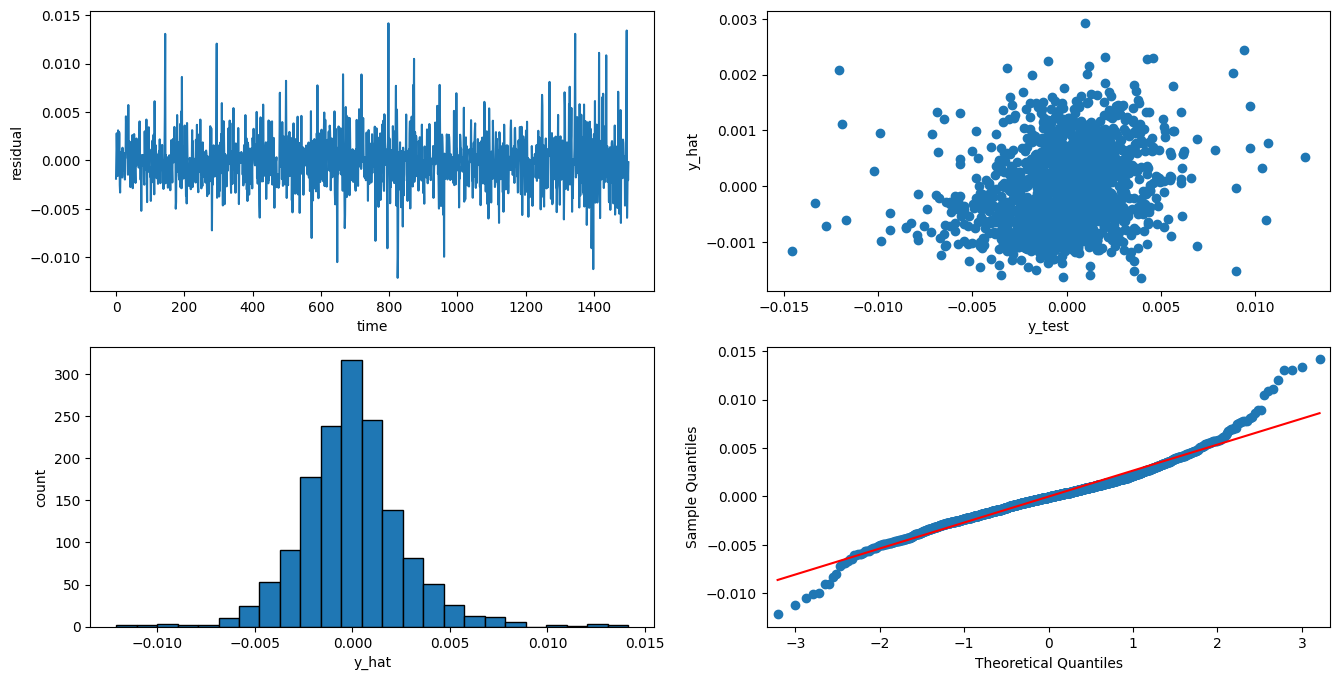

In [41]:
fig, ax = plt.subplots(2, 2, figsize=(16,8))

residuals = y_hat - y_val

ax[0,0].plot(residuals)
ax[0,0].set_xlabel("time")
ax[0,0].set_ylabel("residual")

ax[0,1].scatter(y_val, y_hat)
ax[0,1].set_xlabel("y_test")
ax[0,1].set_ylabel("y_hat")

ax[1,0].hist(residuals, edgecolor='black', bins=25)
ax[1,0].set_xlabel("y_hat")
ax[1,0].set_ylabel("count")

sm.qqplot(residuals.flatten(), line='s', ax=ax[1,1])

plt.show()

In [43]:
import joblib
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(StandardScaler(), Ridge(alpha=1e-1))
pipe.fit(train_data[features].to_numpy(), train_data[target].to_numpy())
joblib.dump(pipe, "ridge_pipe.joblib")

['ridge_pipe.joblib']

## Search for Regime Detecting Variables
Regressing the daily IC from above on variables that may indicate particular regimes.

In [ ]:
daily_ic = (
        data
        .group_by("date", maintain_order=True)
        .agg(
            pl.map_groups(
                exprs=["norm_rank_imb", "return_to_close"],
                function=lambda s: spearmanr(s[0], s[1]).statistic,
                return_dtype=pl.Float64,
                returns_scalar=True,
            ).alias("ic_sign")
        )
        .drop_nulls()
    )
daily_ic

In [ ]:
# Looks uncorrelated
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(daily_ic["ic_sign"], lags=100)
plt.title("Autocorrelation Function (ACF) Plot")
plt.xlabel("Lags")
plt.ylabel("Correlation")
plt.show()

In [ ]:
agg_absorb_ratio = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  (
                      pl.when(pl.col("side") == "B").then(1)
                      .when(pl.col("side") == "A").then(-1)
                      .when(pl.col("side") == "N").then(0)
                      * pl.col('ref_price') * pl.col("total_imbalance_qty")
                  ).alias("dollar_imbalance"),
                  (
                      pl.col("paired_qty") * pl.col('ref_price')
                  ).alias("paired_dollars")
    )
    .group_by(["date"], maintain_order=True)
    .agg(
        (pl.col("dollar_imbalance").sum() / (pl.col("paired_dollars") + pl.col("dollar_imbalance")).sum()).alias("absorb_ratio")
    )
    .collect(engine="streaming")
)
agg_absorb_ratio

In [ ]:
ic_data = (
    daily_ic
    .join(agg_absorb_ratio, on="date")
)
ic_data

In [ ]:
import statsmodels.api as sm
X = sm.add_constant(ic_data['absorb_ratio'].to_numpy())
y = ic_data['ic_sign'].to_numpy()

model = sm.OLS(y, X).fit()
print(model.summary())


In [ ]:
# ======================================================================
# Regime-feature screen: regress daily IC (and |IC|) on day-level features
# Target = continuous daily IC of the raw imbalance signal (daily_ic["ic_sign"]).
# Every feature is ONE value per day, known at 15:50 (no lookahead).
# NOTE: ind_match_price / collars are EXCLUDED -- they only print at 15:55,
#       after the MOC cutoff, so they are unusable at a 15:50 decision.
# ======================================================================
import statsmodels.api as sm

# ---- per-name auction snapshot at 15:50 (first imbalance print >= 15:50) ----
imb_snap = (
    adapter.scan_data(tickers=UNIVERSE, start_date=START, end_date=END,
                      dataset=DATASET, schema="imbalance")
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty",
             "ref_price", "significant_imbalance"])
    .with_columns(pl.col("ts_event").dt.convert_time_zone("America/New_York"),
                  pl.col("symbol").cast(pl.Categorical))
    .filter(pl.col("symbol").is_in(ACTIVE_SET),
            pl.col("ts_event").dt.time() >= pl.time(15, 50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col(["side", "total_imbalance_qty", "paired_qty", "ref_price",
                 "significant_imbalance"]).first())
    .with_columns(
        pl.when(pl.col("side") == "B").then(1)
        .when(pl.col("side") == "A").then(-1).otherwise(0).alias("sign"),
    )
    .with_columns(
        (pl.col("sign") * pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("signed_imb_dollars"),
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("imb_dollars"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
    )
    .collect(engine="streaming")
)

# ---- A/B: imbalance-book day features ----
day_imb = (
    imb_snap.group_by("date", maintain_order=True)
    .agg(
        pl.col("sign").mean().abs().alias("breadth"),                                              # A: one-sidedness
        (pl.col("signed_imb_dollars").sum() / pl.col("paired_dollars").sum()).alias("net_signed_imb"),   # A: net directional pressure
        (pl.col("imb_dollars").sum() / (pl.col("paired_dollars") + pl.col("imb_dollars")).sum()).alias("absorb_ratio_mag"),  # B: unsigned absorption
        (~pl.col("significant_imbalance").cast(pl.Utf8).is_in(["0", "N", "~", ""])).mean().alias("sig_imb_frac"),  # B: significant-flag prevalence
        pl.col("paired_dollars").sum().alias("tot_paired_dollars"),
    )
)

# ---- C/F: price-action day features (from `data`, mids, known at 15:50) ----
day_px = (
    data.group_by("date", maintain_order=True)
    .agg(
        pl.col("recent_return").abs().mean().alias("mkt_vol"),      # C: realized-vol proxy
        pl.col("recent_return").std().alias("xs_disp"),            # C: cross-sectional dispersion
        pl.col("recent_return").mean().alias("mkt_trend"),         # F: signed market move into the close
        pl.col("spread_return").mean().alias("mean_spread"),       # C: liquidity regime
    )
)

# ---- A: auction participation = closing-auction $ / ADV ----
day_adv = avg_daily_dollar_volume.group_by("date", maintain_order=True).agg(pl.col("ADV").sum().alias("tot_adv"))

# ---- D: calendar / forced-flow dummies (all knowable ex-ante) ----
cal = (
    daily_ic.select("date")
    .with_columns(pl.col("date").dt.truncate("1mo").alias("ym"))
    .with_columns(
        (pl.col("date").dt.weekday() == 5).cast(pl.Int8).alias("is_friday"),
        ((pl.col("date").dt.weekday() == 5) & pl.col("date").dt.day().is_between(15, 21)).cast(pl.Int8).alias("is_opex"),
        ((pl.col("date").dt.weekday() == 5) & pl.col("date").dt.day().is_between(15, 21)
         & pl.col("date").dt.month().is_in([3, 6, 9, 12])).cast(pl.Int8).alias("is_quad_witch"),
        pl.col("date").dt.weekday().alias("dow"),
        (pl.col("date") == pl.col("date").max().over("ym")).cast(pl.Int8).alias("is_month_end"),
    )
    .with_columns(((pl.col("is_month_end") == 1) & pl.col("date").dt.month().is_in([3, 6, 9, 12])).cast(pl.Int8).alias("is_quarter_end"))
    .drop("ym")
)

# ---- assemble one day-level table keyed on date ----
day_features = (
    daily_ic.rename({"ic_sign": "ic"})            # daily_ic["ic_sign"] is the continuous Spearman IC
    .join(day_imb, on="date")
    .join(day_px, on="date")
    .join(day_adv, on="date")
    .join(cal, on="date")
    .sort("date")
    .with_columns(
        (pl.col("tot_paired_dollars") / pl.col("tot_adv")).alias("auction_participation"),  # A
        pl.col("ic").shift(1).alias("ic_lag1"),    # E: persistence (ACF already ~flat)
        pl.col("ic").abs().alias("abs_ic"),
    )
)

# ---- univariate OLS screen: each feature vs continuous IC and |IC| ----
feature_cols = ["breadth", "net_signed_imb", "absorb_ratio_mag", "sig_imb_frac",
                "auction_participation", "mkt_vol", "xs_disp", "mkt_trend", "mean_spread",
                "is_friday", "is_opex", "is_quad_witch", "is_month_end", "is_quarter_end",
                "dow", "ic_lag1"]

pdf = day_features.to_pandas()
rows = []
for tgt in ["ic", "abs_ic"]:
    for f in feature_cols:
        sub = pdf[[tgt, f]].dropna()
        if len(sub) < 30 or sub[f].std() == 0:
            continue
        xz = (sub[f] - sub[f].mean()) / sub[f].std()            # z-score so betas are comparable
        m = sm.OLS(sub[tgt].to_numpy(), sm.add_constant(xz.to_numpy())).fit()
        rows.append({"target": tgt, "feature": f, "beta_per_sd": m.params[1],
                     "t": m.tvalues[1], "p": m.pvalues[1], "r2": m.rsquared, "n": len(sub)})

bonf = 0.05 / len(feature_cols)
results = (
    pl.DataFrame(rows)
    .with_columns((pl.col("p") < bonf).alias("sig_bonferroni"))
    .sort(pl.col("t").abs(), descending=True)
)
print(f"Bonferroni threshold (p < 0.05/{len(feature_cols)}) = {bonf:.4f}\n"
      f"Univariate screen, sorted by |t|.  Treat anything not Bonferroni-significant as noise.\n")
with pl.Config(tbl_rows=60, tbl_width_chars=200):
    print(results)
